# Gaia-4 b: RV only, then RV + Gaia DR4 EAS

Fit the primary star's radial velocities first, then add the EAS prerelease
along-scan astrometry for source **1457486023639239296**. Body 0 is the
star and body 1 is a single companion. The two fits keep
separate samplers and posteriors (`rv_mcmc` / `rv_post` and `mcmc` / `post`).

RVs: [Stefánsson et al. (2025), AJ 169, 107](https://doi.org/10.3847/1538-3881/ada9e1),
[Table 5 at CDS](https://cdsarc.cds.unistra.fr/ftp/J/AJ/169/107/ReadMe).
Astrometry: **ESA/Gaia/DPAC**, [DR4 prerelease](https://www.cosmos.esa.int/web/gaia/dr4-prerelease).
Both inputs must already be in the local `orbitize/example_data` directory.


In [3]:
from pathlib import Path
from copy import copy
from time import perf_counter
import sys
from astropy.time import Time

repo_root = Path("../..").resolve()
if not (repo_root / "orbitize" / "__init__.py").is_file():
    raise FileNotFoundError("Run this notebook from orbitize/docs/tutorials.")
sys.path.insert(0, str(repo_root))

import corner
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
import orbitize
from orbitize import gaia, plot, priors, read_input, sampler, system

# Seed the sampler's NumPy RNG and our bootstrap/draw RNG once here.
np.random.seed(42)
rng = np.random.default_rng(42)

source_id = 1457486023639239296
ref_epoch_mjd = 57936.375  # J2017.5, MJD(TCB)
stellar_mass = 0.644  # Msun; Stefansson et al. (2025), Table 1
stellar_mass_err = 0.024  # Symmetrize the published -0.023/+0.025 Msun errors.

# First run settings for each fit
num_temps = 10
num_walkers = 128
num_threads = 10
burn_steps = 2_000
num_steps = 5_000
thin = 1

## 1. Read and inspect the RVs

The CSV contains 23 RVs: 10 HPF, 8 NEID and 5 FIES. Velocities and formal
errors are in km/s. Published BJD(TDB) timestamps were converted to
MJD(TCB) to match EAS, with the original timestamps retained in the CSV.
We will fit a separate offset and jitter for each instrument.

23 RVs; instruments: FIES, HPF, NEID
RV baseline: 1.43 years


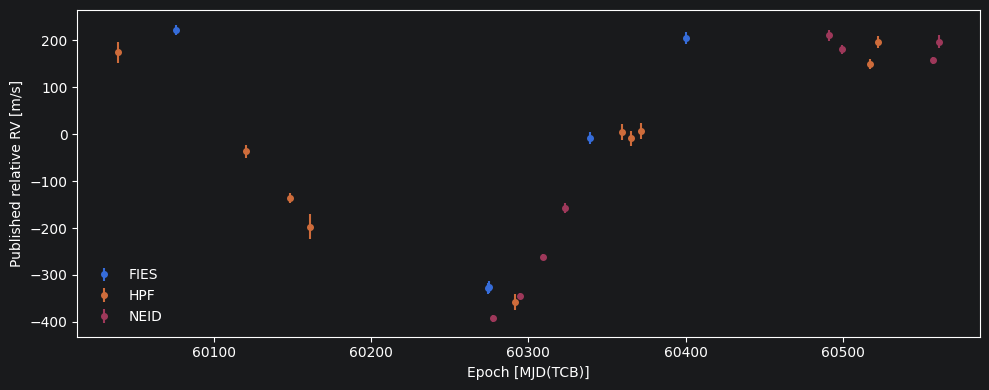

In [4]:
rv_path = Path(orbitize.DATADIR) / "gaia4_rv_stefansson2025.csv"
rv_data = read_input.read_file(str(rv_path))
instruments = np.unique(rv_data["instrument"])
print(f"{len(rv_data)} RVs; instruments: {', '.join(instruments)}")
print(f"RV baseline: {np.ptp(rv_data['epoch']) / 365.25:.2f} years")

fig, ax = plt.subplots(figsize=(10, 4))
for instrument in instruments:
    use = rv_data["instrument"] == instrument
    ax.errorbar(
        rv_data["epoch"][use],
        1_000 * rv_data["quant1"][use],
        yerr=1_000 * rv_data["quant1_err"][use],
        fmt="o",
        ms=4,
        label=instrument,
    )
ax.set(xlabel="Epoch [MJD(TCB)]", ylabel="Published relative RV [m/s]")
ax.legend(frameon=False)
fig.tight_layout()

## 2. RV system and shared priors

Use **SemiAmp** for both fits: it samples period $P$ and stellar RV amplitude
$K$, deriving relative semimajor axis and companion mass through the basis.
There is **no separate companion-mass prior** in this basis. A prior on $K$
induces a different mass prior from a Standard-basis mass prior.
The stellar mass estimate is from the paper's SED/
isochrone analysis, which used Gaia distance. See [Table 1 and Section 3](https://arxiv.org/html/2410.05654v1#S3).

In [5]:
def set_shared_priors(fit_system):
    """Set identical shared priors for the RV-only and joint System objects.

    Args:
        fit_system (orbitize.system.System): SemiAmp system updated in place.
    """
    shared = {
        "per1": priors.LogUniformPrior(0.1, 10.0),
        "K1": priors.LogUniformPrior(0.001, 2.0),
        "ecc1": priors.UniformPrior(0.0, 0.95),
        "inc1": priors.SinPrior(),
        "aop1": priors.UniformPrior(0.0, 2 * np.pi),
        "pan1": priors.UniformPrior(0.0, 2 * np.pi),
        "tau1": priors.UniformPrior(0.0, 1.0),
        "plx": priors.UniformPrior(5.0, 25.0),
    }
    for name, prior in shared.items():
        fit_system.sys_priors[fit_system.param_idx[name]] = prior
    for instrument in fit_system.rv_instruments:
        fit_system.sys_priors[fit_system.param_idx[f"gamma_{instrument}"]] = (
            priors.UniformPrior(-2.0, 2.0)
        )
        fit_system.sys_priors[fit_system.param_idx[f"sigma_{instrument}"]] = (
            priors.LogUniformPrior(1e-4, 0.1)
        )


# Constructor parallax placeholders are replaced by the uniform prior above.
rv_system = system.System(
    1,
    rv_data,
    stellar_mass,
    13.6,
    mass_err=stellar_mass_err,
    plx_err=1.0,
    fit_secondary_mass=True,
    tau_ref_epoch=ref_epoch_mjd,
    fitting_basis="SemiAmp",
)
set_shared_priors(rv_system)
rv_idx = rv_system.param_idx
print("RV fitting basis:", rv_system.fitting_basis)

RV fitting basis: SemiAmp


## 3. Fit the RVs

Let's fit for the RV data by itself first.

In [6]:
rv_mcmc = sampler.MCMC(
    rv_system,
    num_temps=num_temps,
    num_walkers=num_walkers,
    num_threads=num_threads,
)
rv_mcmc.check_prior_support()
print("RV sampler initialized; sampling has not started.")

RV sampler initialized; sampling has not started.


In [7]:
start = perf_counter()
rv_run = rv_mcmc.run_sampler(
    num_walkers * num_steps,
    burn_steps=burn_steps,
    thin=thin,
)
rv_post = np.asarray(rv_mcmc.results.post).copy()
print(f"RV run took {(perf_counter() - start) / 60:.1f} minutes")
print("Mean acceptance per temperature:", rv_run.acceptance_fraction.mean(axis=1))
print("Swap acceptance:", rv_run.tswap_acceptance_fraction)
print(f"Best RV lnlike: {np.nanmax(rv_mcmc.results.lnlike):.3f}")

Starting Burn in


/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:568: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:568: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarn

2000/2000 steps of burn-in complete
Burn in complete. Sampling posterior now.
5000/5000 steps completed
Run complete
RV run took 12.1 minutes
Mean acceptance per temperature: [0.04318906 0.04102187 0.03865156 0.04617187 0.06875312 0.09579844
 0.10558594 0.10679219 0.10086094 0.08706406]
Swap acceptance: [0.17851719 0.18938516 0.23429375 0.25017109 0.31595547 0.447075
 0.50502969 0.51527969 0.50555703 0.49636719]
Best RV lnlike: 57.970


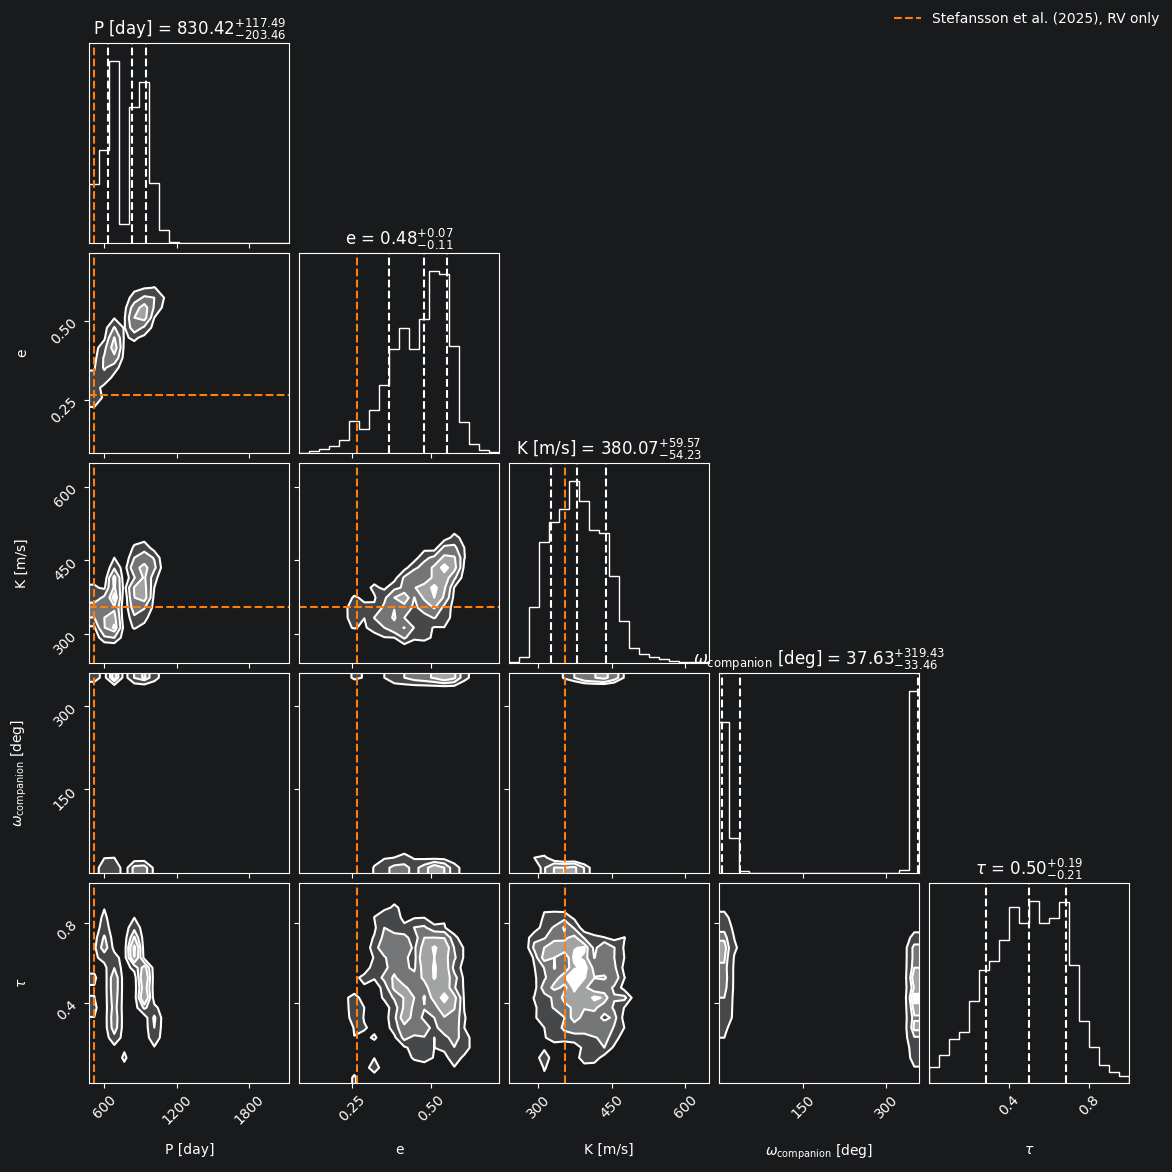

In [8]:
rv_corner_params = ["per1", "ecc1", "K1", "aop1", "tau1"]
rv_draws = rng.choice(len(rv_post), size=min(20_000, len(rv_post)), replace=False)
rv_corner_samples = rv_post[rv_draws][
    :, [rv_idx[name] for name in rv_corner_params]
].copy()
rv_corner_samples[:, 0] *= 365.25
rv_corner_samples[:, 2] *= 1_000
rv_corner_samples[:, 3] = np.rad2deg(rv_corner_samples[:, 3])
rv_corner_figure = corner.corner(
    rv_corner_samples,
    labels=["P [day]", "e", "K [m/s]", r"$\omega_{\rm companion}$ [deg]", r"$\tau$"],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    plot_datapoints=False,
    fill_contours=True,
    max_n_ticks=3,
)
published_rv = [513.0, 0.263, 355.0, None, None]
corner.overplot_lines(
    rv_corner_figure, published_rv, color="tab:orange", linestyle="--"
)
rv_corner_figure.axes[0].plot(
    [],
    [],
    color="tab:orange",
    linestyle="--",
    label="Stefansson et al. (2025), RV only",
)
rv_corner_figure.legend(
    *rv_corner_figure.axes[0].get_legend_handles_labels(),
    loc="upper right",
    frameon=False,
)

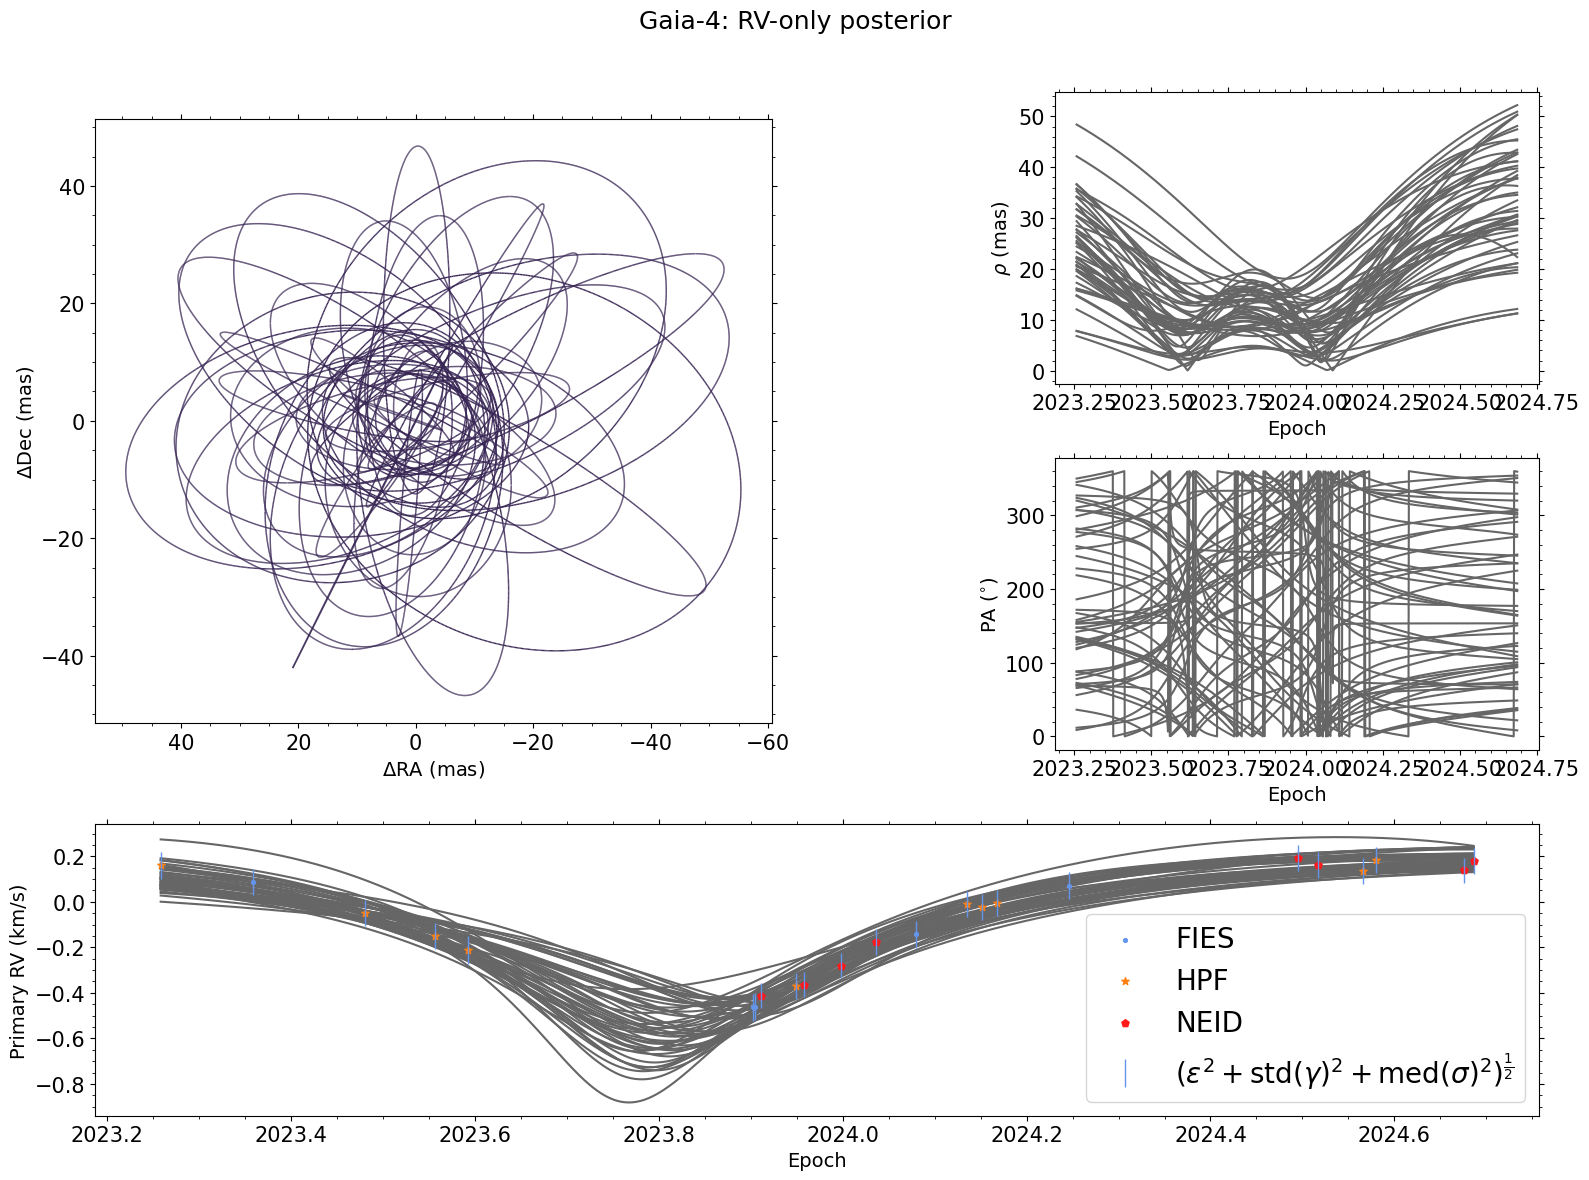

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from orbitize import plot

rv_epochs = np.asarray(rv_mcmc.system.data_table["epoch"], dtype=float)

with plt.style.context("default"):
    rv_plotter = plot.Plotter(
        rv_mcmc.results,
        object_to_plot=1,
        start=float(rv_epochs.min()),
        end=float(rv_epochs.max()),
        time_format="mjd",
        num_orbits_to_plot=50,
        num_epochs_to_plot=1_000,
        rv_time_series=True,
    )

    rv_model_figure = rv_plotter.plot_orbits(
        rv_time_series=True,
        plot_astrometry=False,
        show_colorbar=False,
        use_cmap=False,
        sep_pa_color="0.4",
        fontsize=14,
    )

    # Make the RV-only sky curves visible.
    sky_ax = rv_model_figure.axes[0]
    sky_ax.autoscale(enable=True, axis="both")
    sky_ax.autoscale_view()
    sky_ax.set_aspect("equal", adjustable="box")

    rv_model_figure.suptitle("Gaia-4: RV-only posterior", fontsize=18)
    rv_model_figure.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

In [10]:
from datetime import datetime
from pathlib import Path

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
rv_output_path = Path(f"Gaia4_RV_only_results_{stamp}.hdf5")

if rv_output_path.exists():
    raise FileExistsError(rv_output_path)

rv_mcmc.results.save_results(str(rv_output_path))
print(f"Saved: {rv_output_path.resolve()}")

Saved: /Users/clary/Projects/orbitize/docs/tutorials/Gaia4_RV_only_results_20261104_173832_401451.hdf5


## 5. Read and reduce the EAS astrometry

Bootstrap **within each transit once**, with 500
resamples. Use the original CCD median as the transit position and the
bootstrap standard deviation of the median as its uncertainty, with floor
$\mathrm{median}(\sigma_{\rm IPD})/\sqrt{N_{\rm CCD}}$.

This source has 824 selected CCD measurements in 93 transits. The reduction
uses the mean CCD epoch and first CCD's scan angle/parallax factor.

824 CCDs -> 93 transits
Gaia baseline: 4.94 years


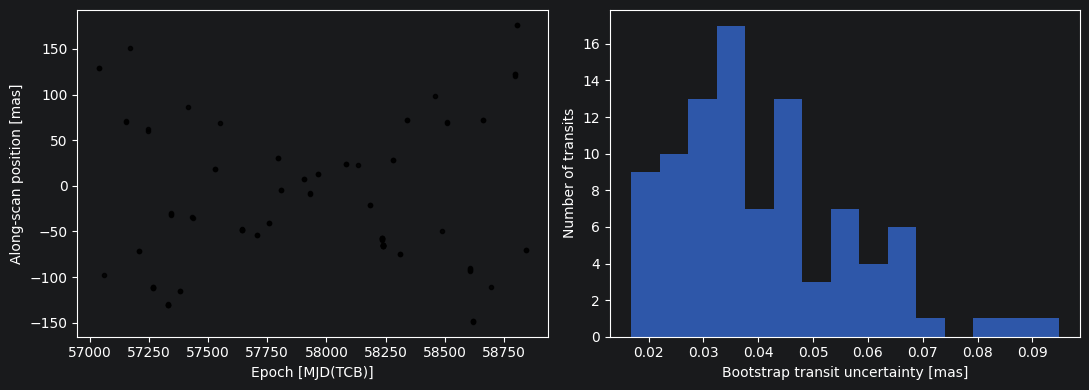

In [12]:
# get data
xml_path = Path(orbitize.DATADIR) / "GAIA_DR4_PRERELEASE_EPOCH_ASTROMETRY_RAW.xml"
ccd_data = read_input.from_dl2(xml_path, source_id)

# combine transits
data = read_input.combine_transits(ccd_data, n_boot=500, rng=rng)

# read in combined transit data
time_mjd = np.asarray(data["obs_time_tcb"], dtype=float)
al = np.asarray(data["centroid_pos_al"], dtype=float)
al_err = np.asarray(data["centroid_pos_error_al"], dtype=float)
psi = np.asarray(data["scan_pos_angle"], dtype=float)
parallax_factor = np.asarray(data["parallax_factor_al"], dtype=float)
dt_yr = (time_mjd - ref_epoch_mjd) / 365.25
sinpsi, cospsi = np.sin(psi), np.cos(psi)

print(f"{len(ccd_data)} CCDs -> {len(data)} transits")
print(f"Gaia baseline: {np.ptp(time_mjd) / 365.25:.2f} years")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].errorbar(time_mjd, al, yerr=al_err, fmt="k.", alpha=0.8)
axes[0].set(xlabel="Epoch [MJD(TCB)]", ylabel="Along-scan position [mas]")
axes[1].hist(al_err, bins=15, alpha=0.75)
axes[1].set(xlabel="Bootstrap transit uncertainty [mas]", ylabel="Number of transits")
fig.tight_layout()

## 6. Joint system

The RV likelihood receives the original RV table once. Gaia receives the
93 row reduced table. The shared priors are exactly
the same as in the RV fit. Additional terms are a Gaia jitter with log-uniform
prior 0.0001–10 mas and the basis's four freely sampled linear parameters:
position offsets and proper motion, each uniform on −10,000–10,000
(mas for offsets, mas/yr for proper motions).


In [13]:
dr4 = gaia.DR4LogProb(
    source_id,
    data,
    ref_epoch_mjd=ref_epoch_mjd,
    jitter_prior=priors.LogUniformPrior(1e-4, 10.0),
)
my_sys = system.System(
    1,
    rv_data,
    stellar_mass,
    13.6,
    mass_err=stellar_mass_err,
    plx_err=1.0,
    fit_secondary_mass=True,
    gaia=dr4,
    tau_ref_epoch=ref_epoch_mjd,
    fitting_basis="SemiAmp",
)
set_shared_priors(my_sys)
idx = my_sys.param_idx
assert dr4.n_obs == len(data)
assert my_sys.gaia.n_obs == len(data)
assert len(my_sys.data_table) == len(rv_data)
print(f"Joint likelihood: {len(rv_data)} RVs + {my_sys.gaia.n_obs} Gaia transits")

Joint likelihood: 23 RVs + 93 Gaia transits


## 7. Initialize from RV draws, keeping orientation broad

Copy shared native SemiAmp coordinates from RV posterior draws within 2
log-likelihood units of the best RV draw,
**excluding inclination and LAN**. Those angles and Gaia jitter retain their
joint prior draws. The basis recomputes mass at each new inclination while
keeping the starting RV period/amplitude.

For each starting orbit, subtract its AL reflex signal and sampled parallax,
then solve a weighted four parameter linear fit:

$$y_j = \mathrm{AL}_j - \varpi P_j - \mathrm{orbit}_{\mathrm{AL},j},$$
$$y_j \simeq \alpha_0\sin\psi_j + \delta_0\cos\psi_j
 + \Delta t_j(\mu_{\alpha*}\sin\psi_j+\mu_\delta\cos\psi_j).$$

The helper only sets sensible starting offsets/proper motions. These four
parameters are **still sampled during MCMC**.


In [14]:
mcmc = sampler.MCMC(
    my_sys,
    num_temps=num_temps,
    num_walkers=num_walkers,
    num_threads=num_threads,
)
sampled_idx = mcmc.sampled_param_idx
positions = mcmc.curr_pos.reshape(-1, mcmc.num_params)

# Both stored posteriors and indices are in the native SemiAmp basis.
warm_names = [
    name for name in sampled_idx if name in rv_idx and name not in ("inc1", "pan1")
]
rv_columns = [rv_idx[name] for name in warm_names]
joint_columns = [sampled_idx[name] for name in warm_names]
# Start near high lnlike RV solutions
rv_logl = np.asarray(rv_mcmc.results.lnlike)
rv_pool = np.asarray(rv_mcmc.results.post)[rv_logl >= np.nanmax(rv_logl) - 2.0]

draws = rng.choice(len(rv_pool), size=len(positions), replace=True)
positions[:, joint_columns] = rv_pool[draws][:, rv_columns]

print(f"RV starting pool: {len(rv_pool)} draws")
full_positions = mcmc._fill_in_fixed_params(positions)
standard_positions = my_sys.basis.to_standard_basis(full_positions.T.copy())
ra, dec, _, _ = my_sys.compute_all_orbits(standard_positions, epochs=dr4.epochs_mjd)
orbit_al = ra[:, 0, :] * sinpsi[:, None] + dec[:, 0, :] * cospsi[:, None]

linear_columns = [sampled_idx[name] for name in ("alpha0", "delta0", "pm_ra", "pm_dec")]

linear_epochs = Time(dr4.epochs_mjd, format="mjd", scale="tcb")
linear_ref = Time(ref_epoch_mjd, format="mjd", scale="tcb").jyear

for walker, params in enumerate(full_positions):
    sigma = np.hypot(al_err, params[idx["dr4_jitter"]])
    target = al - params[idx["plx"]] * parallax_factor - orbit_al[:, walker]
    positions[walker, linear_columns] = gaia.HGCALogProb._linear_pm_fit(
        epochs=linear_epochs,
        raoff_planet=target * sinpsi,
        decoff_planet=target * cospsi,
        epoch_ref_ra=linear_ref,
        epoch_ref_dec=linear_ref,
        sin_phi=cospsi,
        cos_phi=sinpsi,
        errs=sigma,
    )
mcmc.check_prior_support()
print("Joint walkers initialized; sampling has not started.")
print(
    "Inclination range [deg]:",
    np.rad2deg(positions[:, sampled_idx["inc1"]]).min(),
    np.rad2deg(positions[:, sampled_idx["inc1"]]).max(),
)
print(
    "LAN range [deg]:",
    np.rad2deg(positions[:, sampled_idx["pan1"]]).min(),
    np.rad2deg(positions[:, sampled_idx["pan1"]]).max(),
)

RV starting pool: 412 draws
Joint walkers initialized; sampling has not started.
Inclination range [deg]: 0.7949439228677424 177.87547612565325
LAN range [deg]: 0.5209993875597574 359.8021882771069


In [15]:
# start = perf_counter()
run = mcmc.run_sampler(
    num_walkers * num_steps,
    burn_steps=burn_steps,
    thin=thin,
)
post = np.asarray(mcmc.results.post).copy()
print(f"Joint run took {(perf_counter() - start) / 60:.1f} minutes")
print("Mean acceptance per temperature:", run.acceptance_fraction.mean(axis=1))
print("Swap acceptance:", run.tswap_acceptance_fraction)
print(f"Best joint log-likelihood: {np.nanmax(mcmc.results.lnlike):.3f}")
print(f"RV-only posterior retained: {len(rv_post)} draws")

Starting Burn in


/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:568: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:568: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/Users/clary/Projects/orbitize/orbitize/priors.py:568: RuntimeWarn

2000/2000 steps of burn-in complete
Burn in complete. Sampling posterior now.
5000/5000 steps completed
Run complete
Joint run took 71.8 minutes
Mean acceptance per temperature: [0.2405     0.20519531 0.12485625 0.13751563 0.15473906 0.13154844
 0.12397812 0.11428594 0.10745312 0.10142656]
Swap acceptance: [0.20199063 0.12400938 0.07224063 0.08088281 0.04085938 0.12156172
 0.30378125 0.3950625  0.40965156 0.41202344]
Best joint log-likelihood: 222.452
RV-only posterior retained: 640000 draws


## 8. Joint posterior

Convert only a plotting subset to Standard coordinates to obtain the derived
companion mass. The sampled arrays themselves stay in SemiAmp coordinates.
The orange lines are the paper's **Gaia DR3 + RV** comparison.

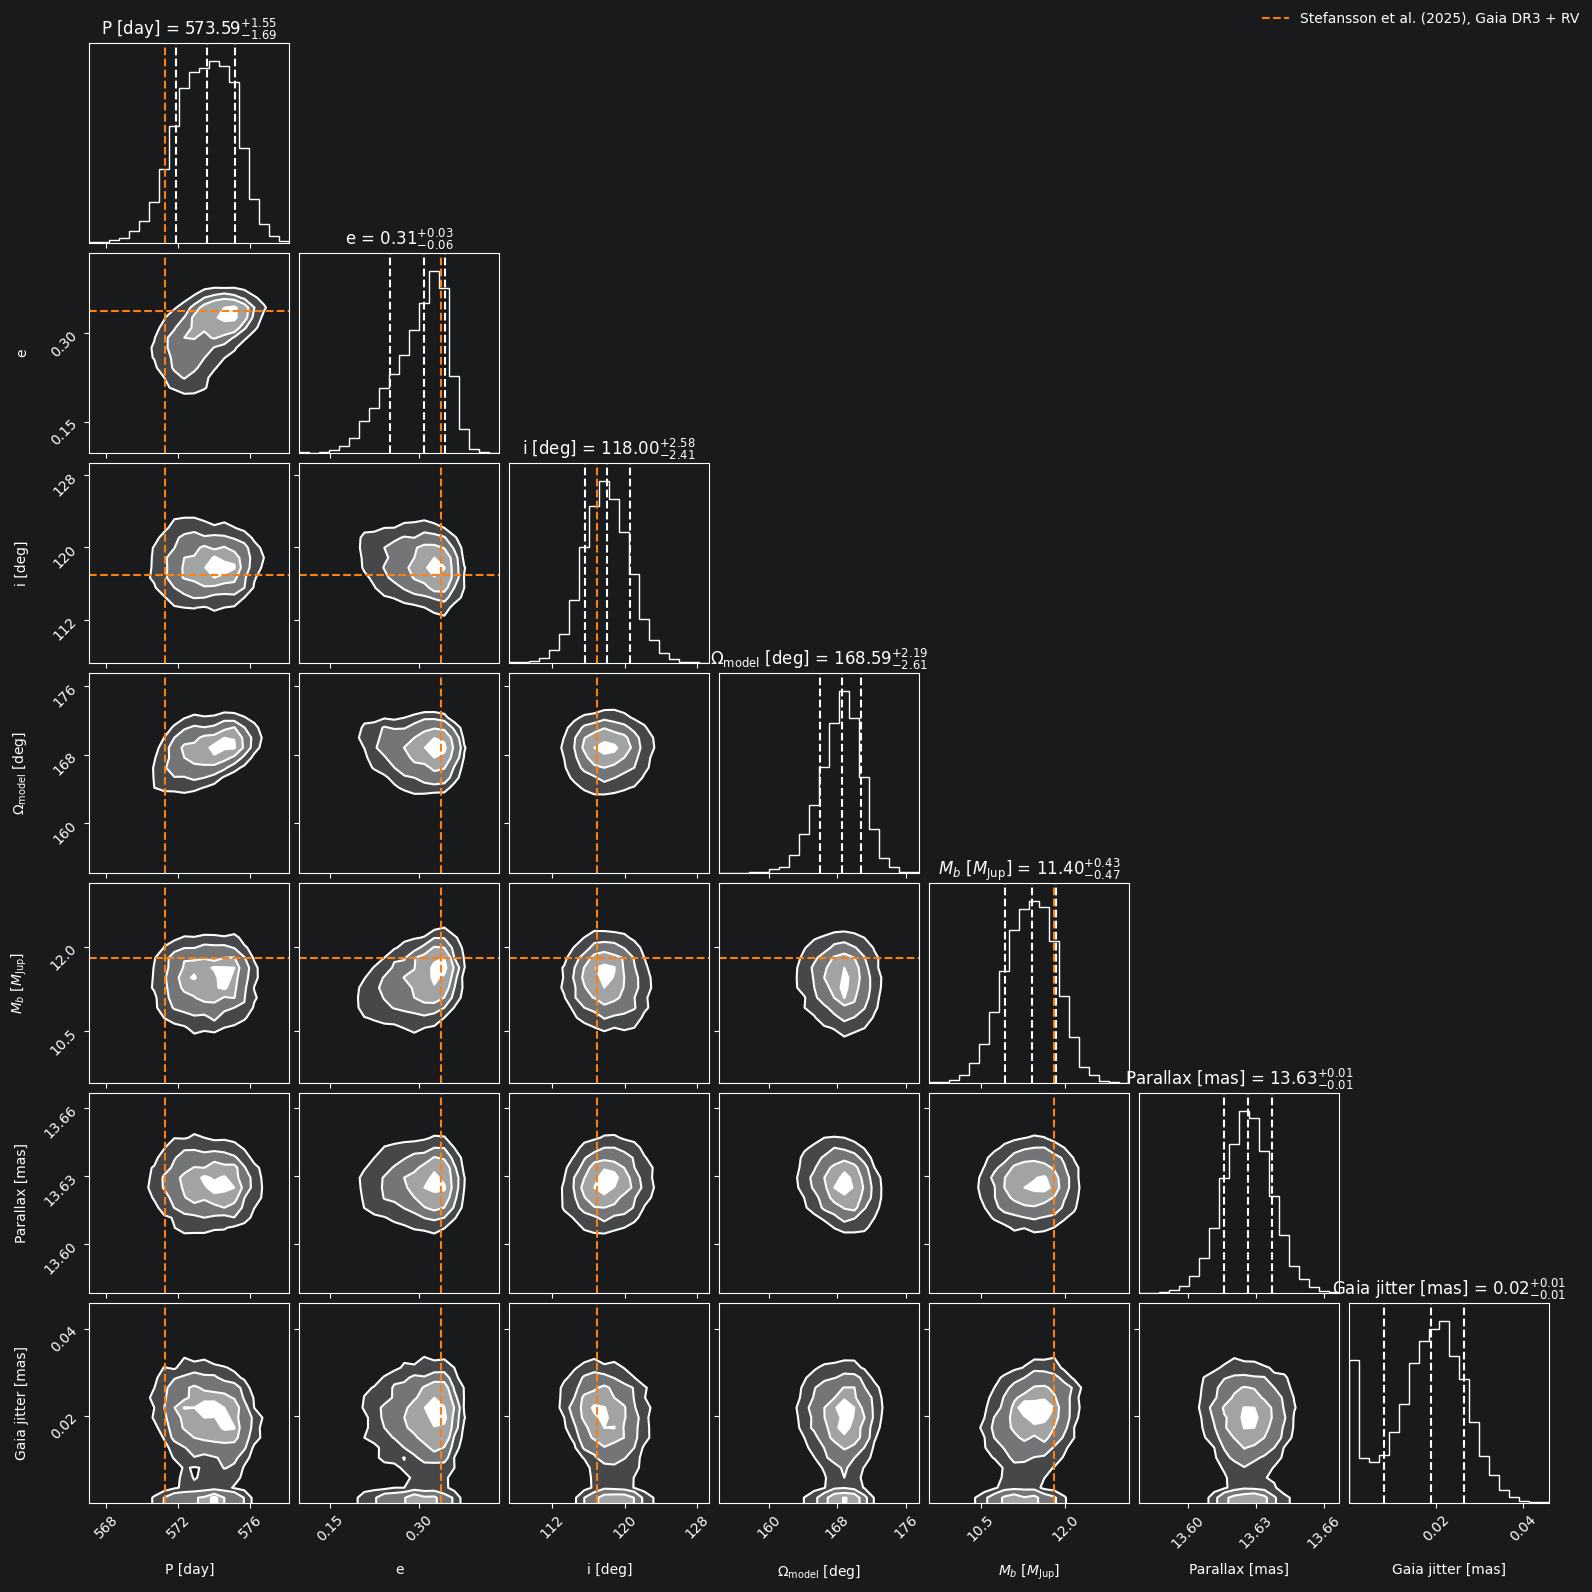

In [16]:
corner_params = ["per1", "ecc1", "inc1", "pan1", "m1", "plx", "dr4_jitter"]
corner_draws = rng.choice(len(post), size=min(20_000, len(post)), replace=False)
plot_post = post[corner_draws]
standard_post = my_sys.basis.to_standard_basis(plot_post.T.copy()).T
standard_idx = my_sys.basis.standard_basis_idx
corner_samples = np.column_stack(
    [
        365.25 * plot_post[:, idx["per1"]],
        plot_post[:, idx["ecc1"]],
        np.rad2deg(plot_post[:, idx["inc1"]]),
        np.rad2deg(plot_post[:, idx["pan1"]]) % 360.0,
        standard_post[:, standard_idx["m1"]] * u.Msun.to(u.Mjup),
        plot_post[:, idx["plx"]],
        plot_post[:, idx["dr4_jitter"]],
    ]
)
corner_figure = corner.corner(
    corner_samples,
    labels=[
        "P [day]",
        "e",
        "i [deg]",
        r"$\Omega_{\rm model}$ [deg]",
        r"$M_b$ [$M_{\rm Jup}$]",
        "Parallax [mas]",
        "Gaia jitter [mas]",
    ],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    plot_datapoints=False,
    fill_contours=True,
    max_n_ticks=3,
)
published_joint = [571.3, 0.338, 116.9, None, 11.8, None, None]
corner.overplot_lines(
    corner_figure, published_joint, color="tab:orange", linestyle="--"
)
corner_figure.axes[0].plot(
    [],
    [],
    color="tab:orange",
    linestyle="--",
    label="Stefansson et al. (2025), Gaia DR3 + RV",
)
corner_figure.legend(
    *corner_figure.axes[0].get_legend_handles_labels(), loc="upper right", frameon=False
)

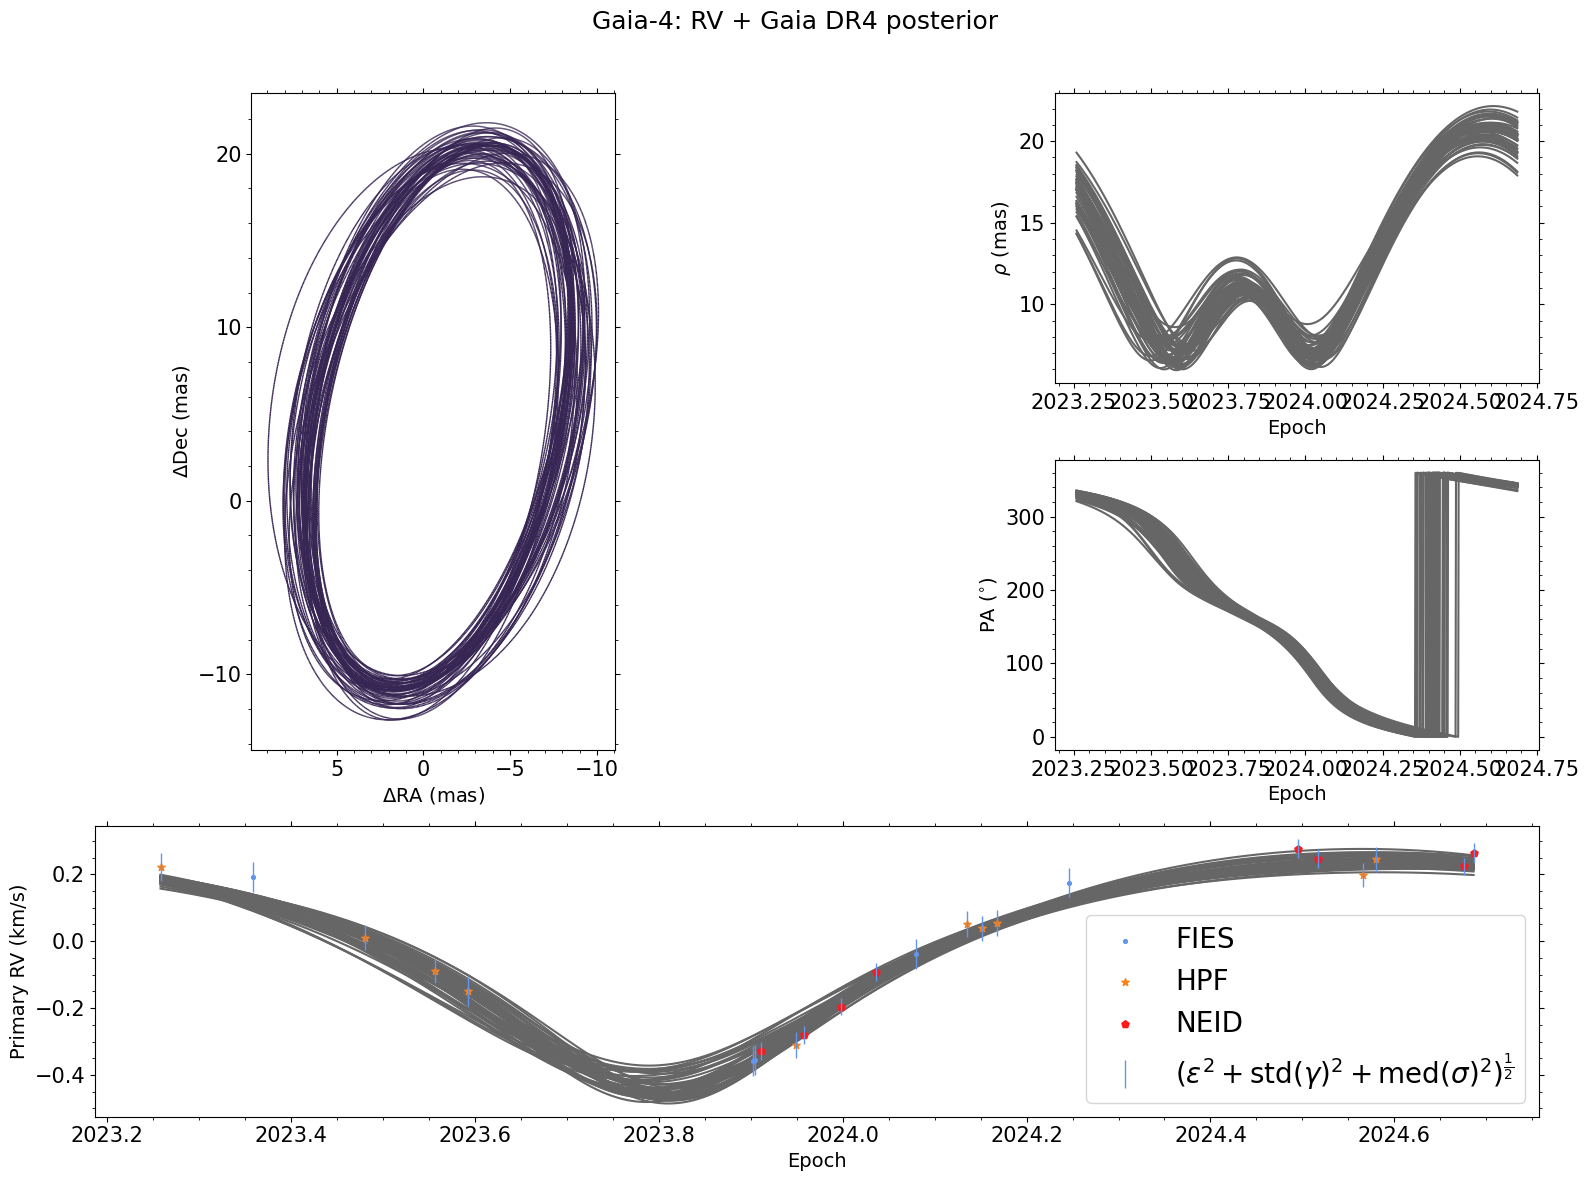

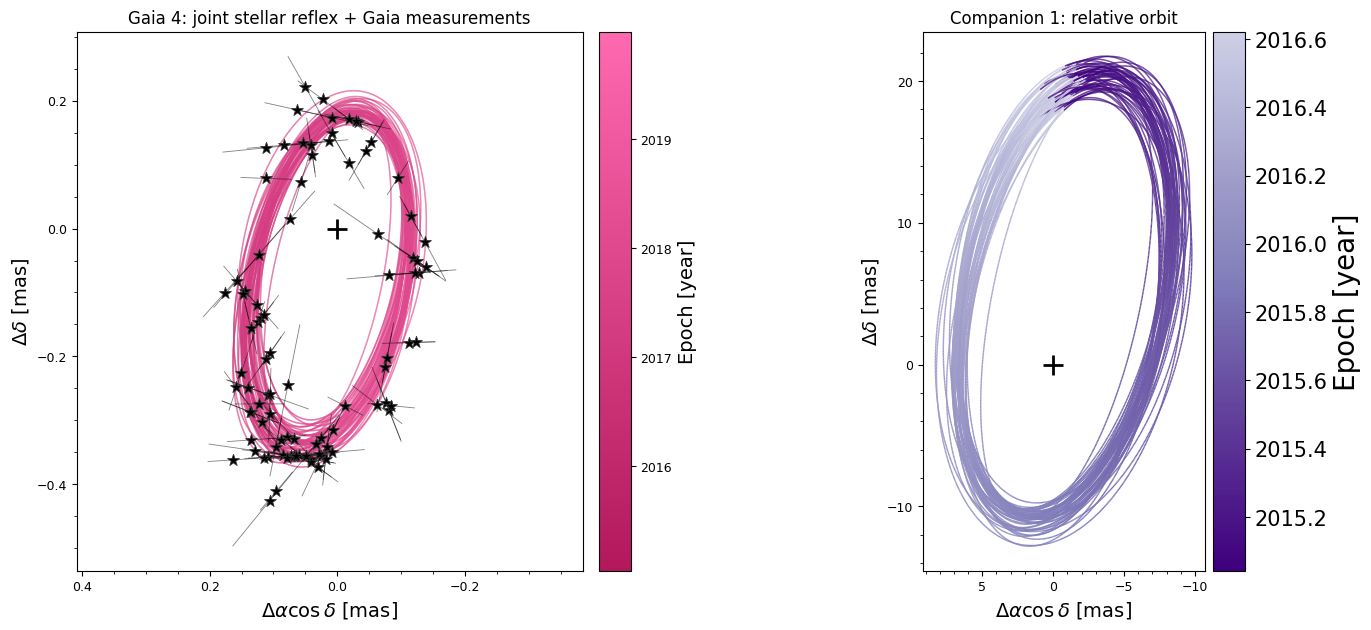

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from orbitize import plot

joint_plot_epochs = np.asarray(mcmc.system.data_table["epoch"], dtype=float)

with plt.style.context("default"):
    # Joint posterior: companion orbit, separation/PA, and stellar RVs.
    joint_plotter = plot.Plotter(
        mcmc.results,
        object_to_plot=1,
        start=float(joint_plot_epochs.min()),
        end=float(joint_plot_epochs.max()),
        time_format="mjd",
        num_orbits_to_plot=50,
        num_epochs_to_plot=1_000,
        rv_time_series=True,
    )

    joint_model_figure = joint_plotter.plot_orbits(
        rv_time_series=True,
        plot_astrometry=False,
        show_colorbar=False,
        use_cmap=False,
        sep_pa_color="0.4",
        fontsize=14,
    )

    sky_ax = joint_model_figure.axes[0]
    sky_ax.autoscale(enable=True, axis="both")
    sky_ax.autoscale_view()
    sky_ax.set_aspect("equal", adjustable="box")

    joint_model_figure.suptitle("Gaia-4: RV + Gaia DR4 posterior", fontsize=18)
    joint_model_figure.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

    # Stellar reflex orbit with Gaia along-scan measurements.
    joint_gaia_figure = plot.plot_dr4_orbit(
        mcmc.results,
        mcmc.system,
        num_orbits_to_plot=50,
        num_epochs_to_plot=1_000,
        include_jitter=True,
        show_colorbar=True,
        fontsize=14,
        include_planet=True,
    )
    joint_gaia_figure.axes[0].set_title(
        "Gaia 4: joint stellar reflex + Gaia measurements"
    )
    plt.show()

## 9. One best-likelihood stellar orbit and residual checks


Text(0.5, 1.0, 'Gaia-4: best-likelihood RV + Gaia EAS stellar orbit')

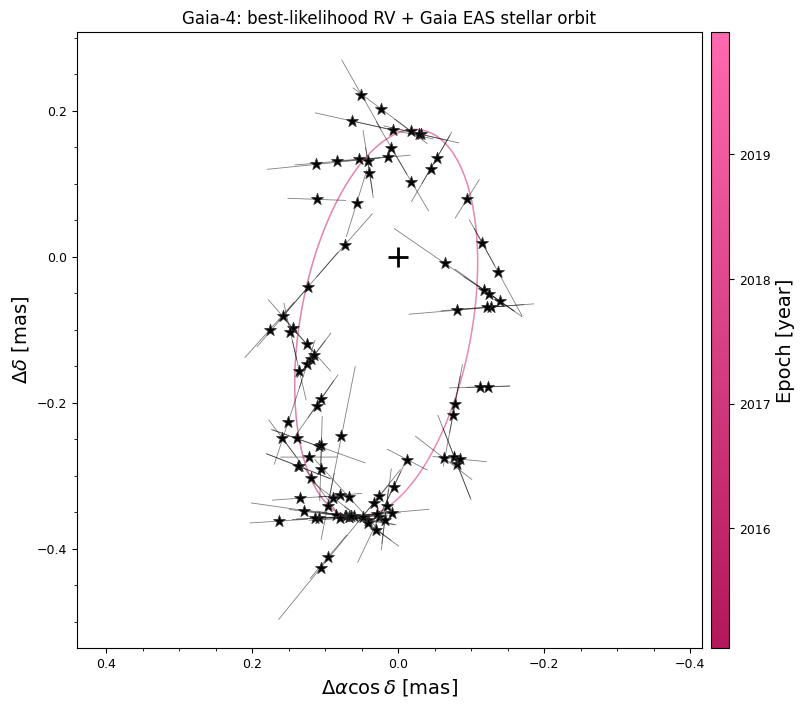

In [19]:
best_idx = np.nanargmax(mcmc.results.lnlike)
best = post[best_idx].copy()
best_results = copy(mcmc.results)
best_results.post = post[[best_idx]]
best_results.lnlike = np.asarray(mcmc.results.lnlike)[[best_idx]]

orbit_figure = best_results.plot_dr4_orbit(
    mcmc.system,
    num_orbits_to_plot=1,
    num_epochs_to_plot=1_000,
    data_params=best,
    include_jitter=True,
    fontsize=14,
)
orbit_figure.axes[0].set_title("Gaia-4: best-likelihood RV + Gaia EAS stellar orbit")

## 10. Save the joint result

The RV-only result was saved separately before the joint fit. Choose a new
filename if either output already exists.

In [21]:
from pathlib import Path
from datetime import datetime

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
output_path = Path(f"Gaia4_RV_DR4_results_{stamp}.hdf5")

mcmc.results.save_results(str(output_path))
print("Saved:", output_path.resolve())

Saved: /Users/clary/Projects/orbitize/docs/tutorials/Gaia_DR4_BH3_results_20261104_205935_187384.hdf5
